# Covariance forecast comparison

Eight covariance recipes across all twelve panel/lookback combinations. The cloud study contains 9,120 scheduled forecast cells. This notebook examines the authenticated full-grid summary; it does not refit models or independently replay every forecast score. QLIKE measures variance forecast loss: lower is better within a panel. It is not a portfolio return.

In [1]:
from pathlib import Path
import hashlib, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p/'pyproject.toml').exists())
report = root / 'reports/risk_forecast_v1'
sha = lambda p: hashlib.sha256(p.read_bytes()).hexdigest()
export = json.loads((report/'export-manifest.json').read_text())
assert (report/'COMPLETE').read_text().strip() == sha(report/'export-manifest.json')
for name, expected in export['outputs_sha256'].items():
    assert sha(report/name) == expected
manifest = json.loads((report/'manifest.json').read_text())
comparison = json.loads((report/'forecast-comparison.json').read_text())
assert manifest['complete'] and manifest['actual_cells'] == 9120
assert not manifest['holdout_outcomes_constructed']
display(pd.Series({'scheduled_cells':9120, 'panel_lookback_combinations':12, 'recipes':8, 'globally_paired_months':len(comparison['fully_paired_96_cell_dates'])}).to_frame('count'))

,count
scheduled_cells,9120
panel_lookback_combinations,12
recipes,8
globally_paired_months,90


## Support and maturity

Each comparison uses the same mature dates for its eight recipes. The global intersection is smaller because long stock windows require more history. A missing or immature cell does not receive a fabricated score.

,scheduled,paired
combination,,
etf8_T63,95,94
etf8_T126,95,94
etf8_T252,95,94
stock50_T63,95,92
stock50_T126,95,92
stock50_T252,95,92
stock100_T63,95,91
stock100_T126,95,91
stock100_T252,95,91


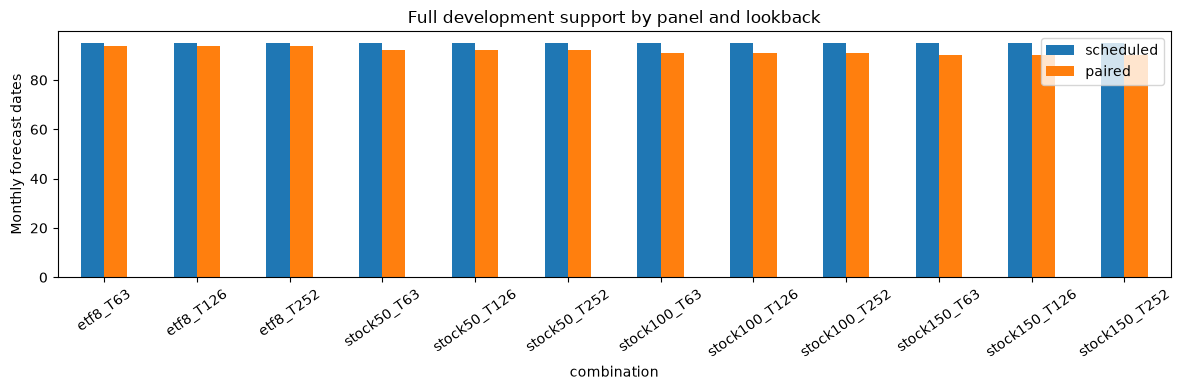

In [2]:
rows, support = [], []
for panel in comparison['panels']:
    key = f"{panel['panel_id']}_T{panel['observations']}"
    assert panel['common_date_count'] == len(set(panel['common_dates']))
    for recipe, loss in panel['mean_qlike_common'].items():
        rows.append({'panel':panel['panel_id'], 'lookback':panel['observations'], 'combination':key, 'recipe':recipe, 'mean_qlike':loss, 'paired_months':panel['common_date_count']})
    support.append({'combination':key, 'scheduled':panel['expected_dates'], 'paired':panel['common_date_count']})
scores = pd.DataFrame(rows)
support = pd.DataFrame(support).set_index('combination')
assert len(scores) == 96 and scores.mean_qlike.map(np.isfinite).all()
display(support)
support.plot.bar(figsize=(12,4), ylabel='Monthly forecast dates', title='Full development support by panel and lookback', rot=35)
plt.tight_layout()
plt.show()

## Relative forecast loss

Subtract the sample covariance loss within each panel/lookback. Negative differences favor the alternative. This keeps comparisons within the same assets, window and paired dates; absolute QLIKE levels should not rank different universes.

recipe,constant_correlation_fixed0p5,ewma_halflife63,ledoit_wolf,oas,pca_K1,pca_K3,pca_K5,sample_ddof1
combination,,,,,,,,
etf8_T126,0.04351,-0.06936,0.02329,0.00925,0.03063,-0.00904,-0.00399,0.0
etf8_T252,0.04080,-0.13182,0.00861,0.00355,0.00747,-0.00369,-0.00256,0.0
etf8_T63,0.03685,-0.01533,0.02786,0.01627,0.06829,-0.00878,0.00025,0.0
stock100_T126,-0.00133,-0.05944,0.05024,0.03082,-0.00033,-0.00389,-0.00347,0.0
stock100_T252,0.00033,-0.13697,0.02473,0.01479,-0.00323,-0.00419,-0.00428,0.0
stock100_T63,-0.00392,-0.02045,0.09870,0.06966,0.81187,-0.00251,-0.00324,0.0
stock150_T126,-0.00497,-0.06285,0.05275,0.03425,0.01273,-0.00272,-0.00273,0.0
stock150_T252,-0.00164,-0.13811,0.02635,0.01605,-0.00273,-0.00295,-0.00314,0.0
stock150_T63,-0.00703,-0.02030,0.10156,0.07696,0.38715,-0.00179,-0.00228,0.0


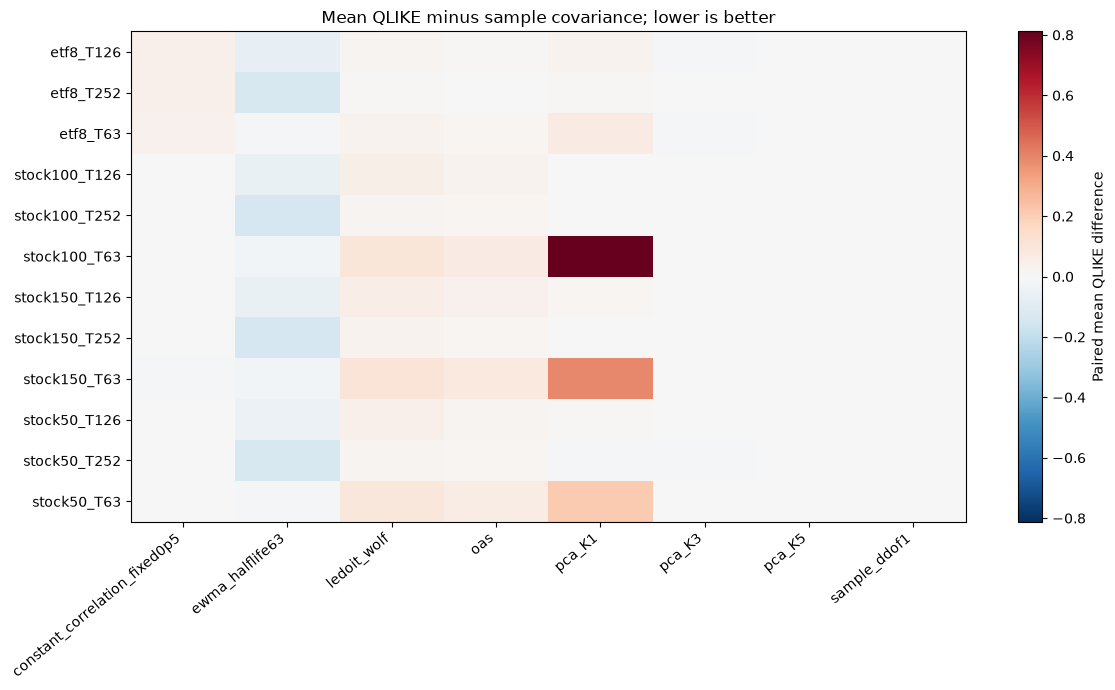

In [3]:
wide = scores.pivot(index='combination', columns='recipe', values='mean_qlike').sort_index()
relative = wide.sub(wide['sample_ddof1'], axis=0)
display(relative.round(5))
limit = abs(relative.to_numpy()).max()
fig, ax = plt.subplots(figsize=(12,7))
image = ax.imshow(relative, cmap='RdBu_r', vmin=-limit, vmax=limit, aspect='auto')
ax.set_xticks(range(len(relative.columns)), relative.columns, rotation=40, ha='right')
ax.set_yticks(range(len(relative)), relative.index)
ax.set_title('Mean QLIKE minus sample covariance; lower is better')
fig.colorbar(image, ax=ax, label='Paired mean QLIKE difference')
plt.tight_layout()
plt.show()

## Lookback sensitivity

Plot every recipe rather than presenting one winning number. These development comparisons inform the separate economic study. They do not establish out-of-sample superiority, statistical significance or trading performance.

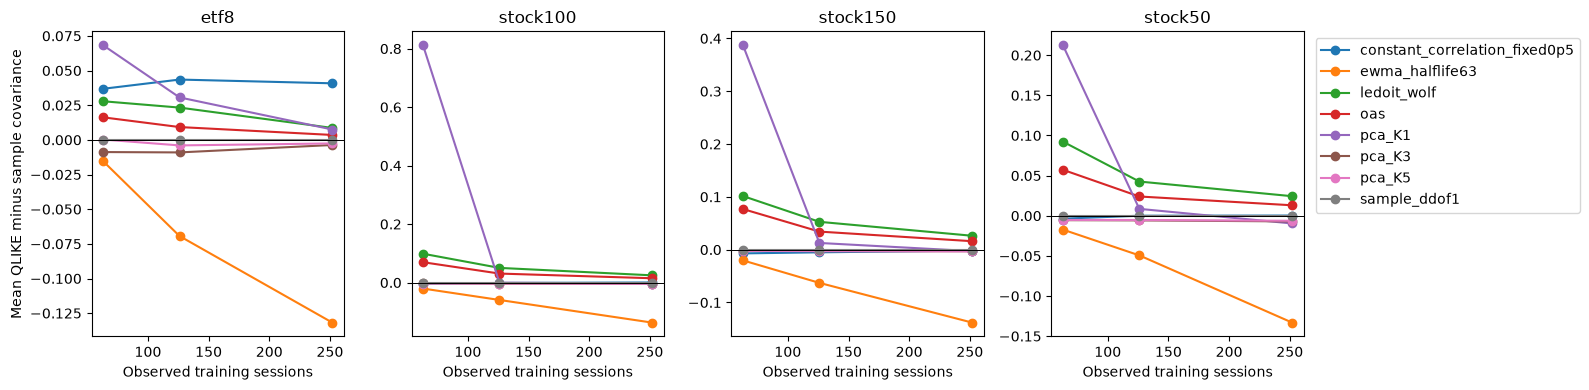

,recipe,mean_qlike,paired_months
combination,,,
etf8_T126,ewma_halflife63,-8.562379,94
etf8_T252,ewma_halflife63,-8.543222,94
etf8_T63,ewma_halflife63,-8.597526,94
stock100_T126,ewma_halflife63,-7.532519,91
stock100_T252,ewma_halflife63,-7.501511,91
stock100_T63,ewma_halflife63,-7.573749,91
stock150_T126,ewma_halflife63,-7.493532,90
stock150_T252,ewma_halflife63,-7.463124,90
stock150_T63,ewma_halflife63,-7.542433,90


In [4]:
panels = sorted(scores.panel.unique())
fig, axes = plt.subplots(1,len(panels), figsize=(16,4), sharex=True)
for panel, ax in zip(panels, np.atleast_1d(axes)):
    subset = scores[scores.panel.eq(panel)]
    baseline = subset[subset.recipe.eq('sample_ddof1')].set_index('lookback').mean_qlike
    for recipe, group in subset.groupby('recipe'):
        group = group.sort_values('lookback')
        ax.plot(group.lookback, group.mean_qlike - group.lookback.map(baseline), marker='o', label=recipe)
    ax.axhline(0, color='black', lw=.7)
    ax.set_title(panel)
    ax.set_xlabel('Observed training sessions')
axes[0].set_ylabel('Mean QLIKE minus sample covariance')
axes[-1].legend(bbox_to_anchor=(1.02,1), loc='upper left')
plt.tight_layout()
plt.show()
display(scores.loc[scores.groupby('combination').mean_qlike.idxmin(), ['combination','recipe','mean_qlike','paired_months']].set_index('combination'))

## Full-grid calibration and uncertainty

All 9,120 scheduled cells are retained. The 8,808 valid scalar losses were replayed from authenticated cloud exports. Calibration bins describe development forecasts; they do not fit a calibration model. Paired intervals use 2,000 circular scheduled-month block resamples, preserving missing months and common recipe dates. These unadjusted intervals do not select a trading winner.

score_status       not_mature_by_information_cutoff  unresolved_future_panel  \
panel    lookback                                                              
etf8     63                                       8                        0   
         126                                      8                        0   
         252                                      8                        0   
stock100 63                                       8                       24   
         126                                      8                       24   
         252                                      8                       24   
stock150 63                                       8                       32   
         126                                      8                       32   
         252                                      8                       32   
stock50  63                                       8                       16   
         126                                      8                       16   
         252                                      8                       16   

score_status       valid  
panel    lookback         
etf8     63          752  
         126         752  
         252         752  
stock100 63          728  
         126         728  
         252         728  
stock150 63          720  
         126         720  
         252         720  
stock50  63          736  
         126         736  
         252         736

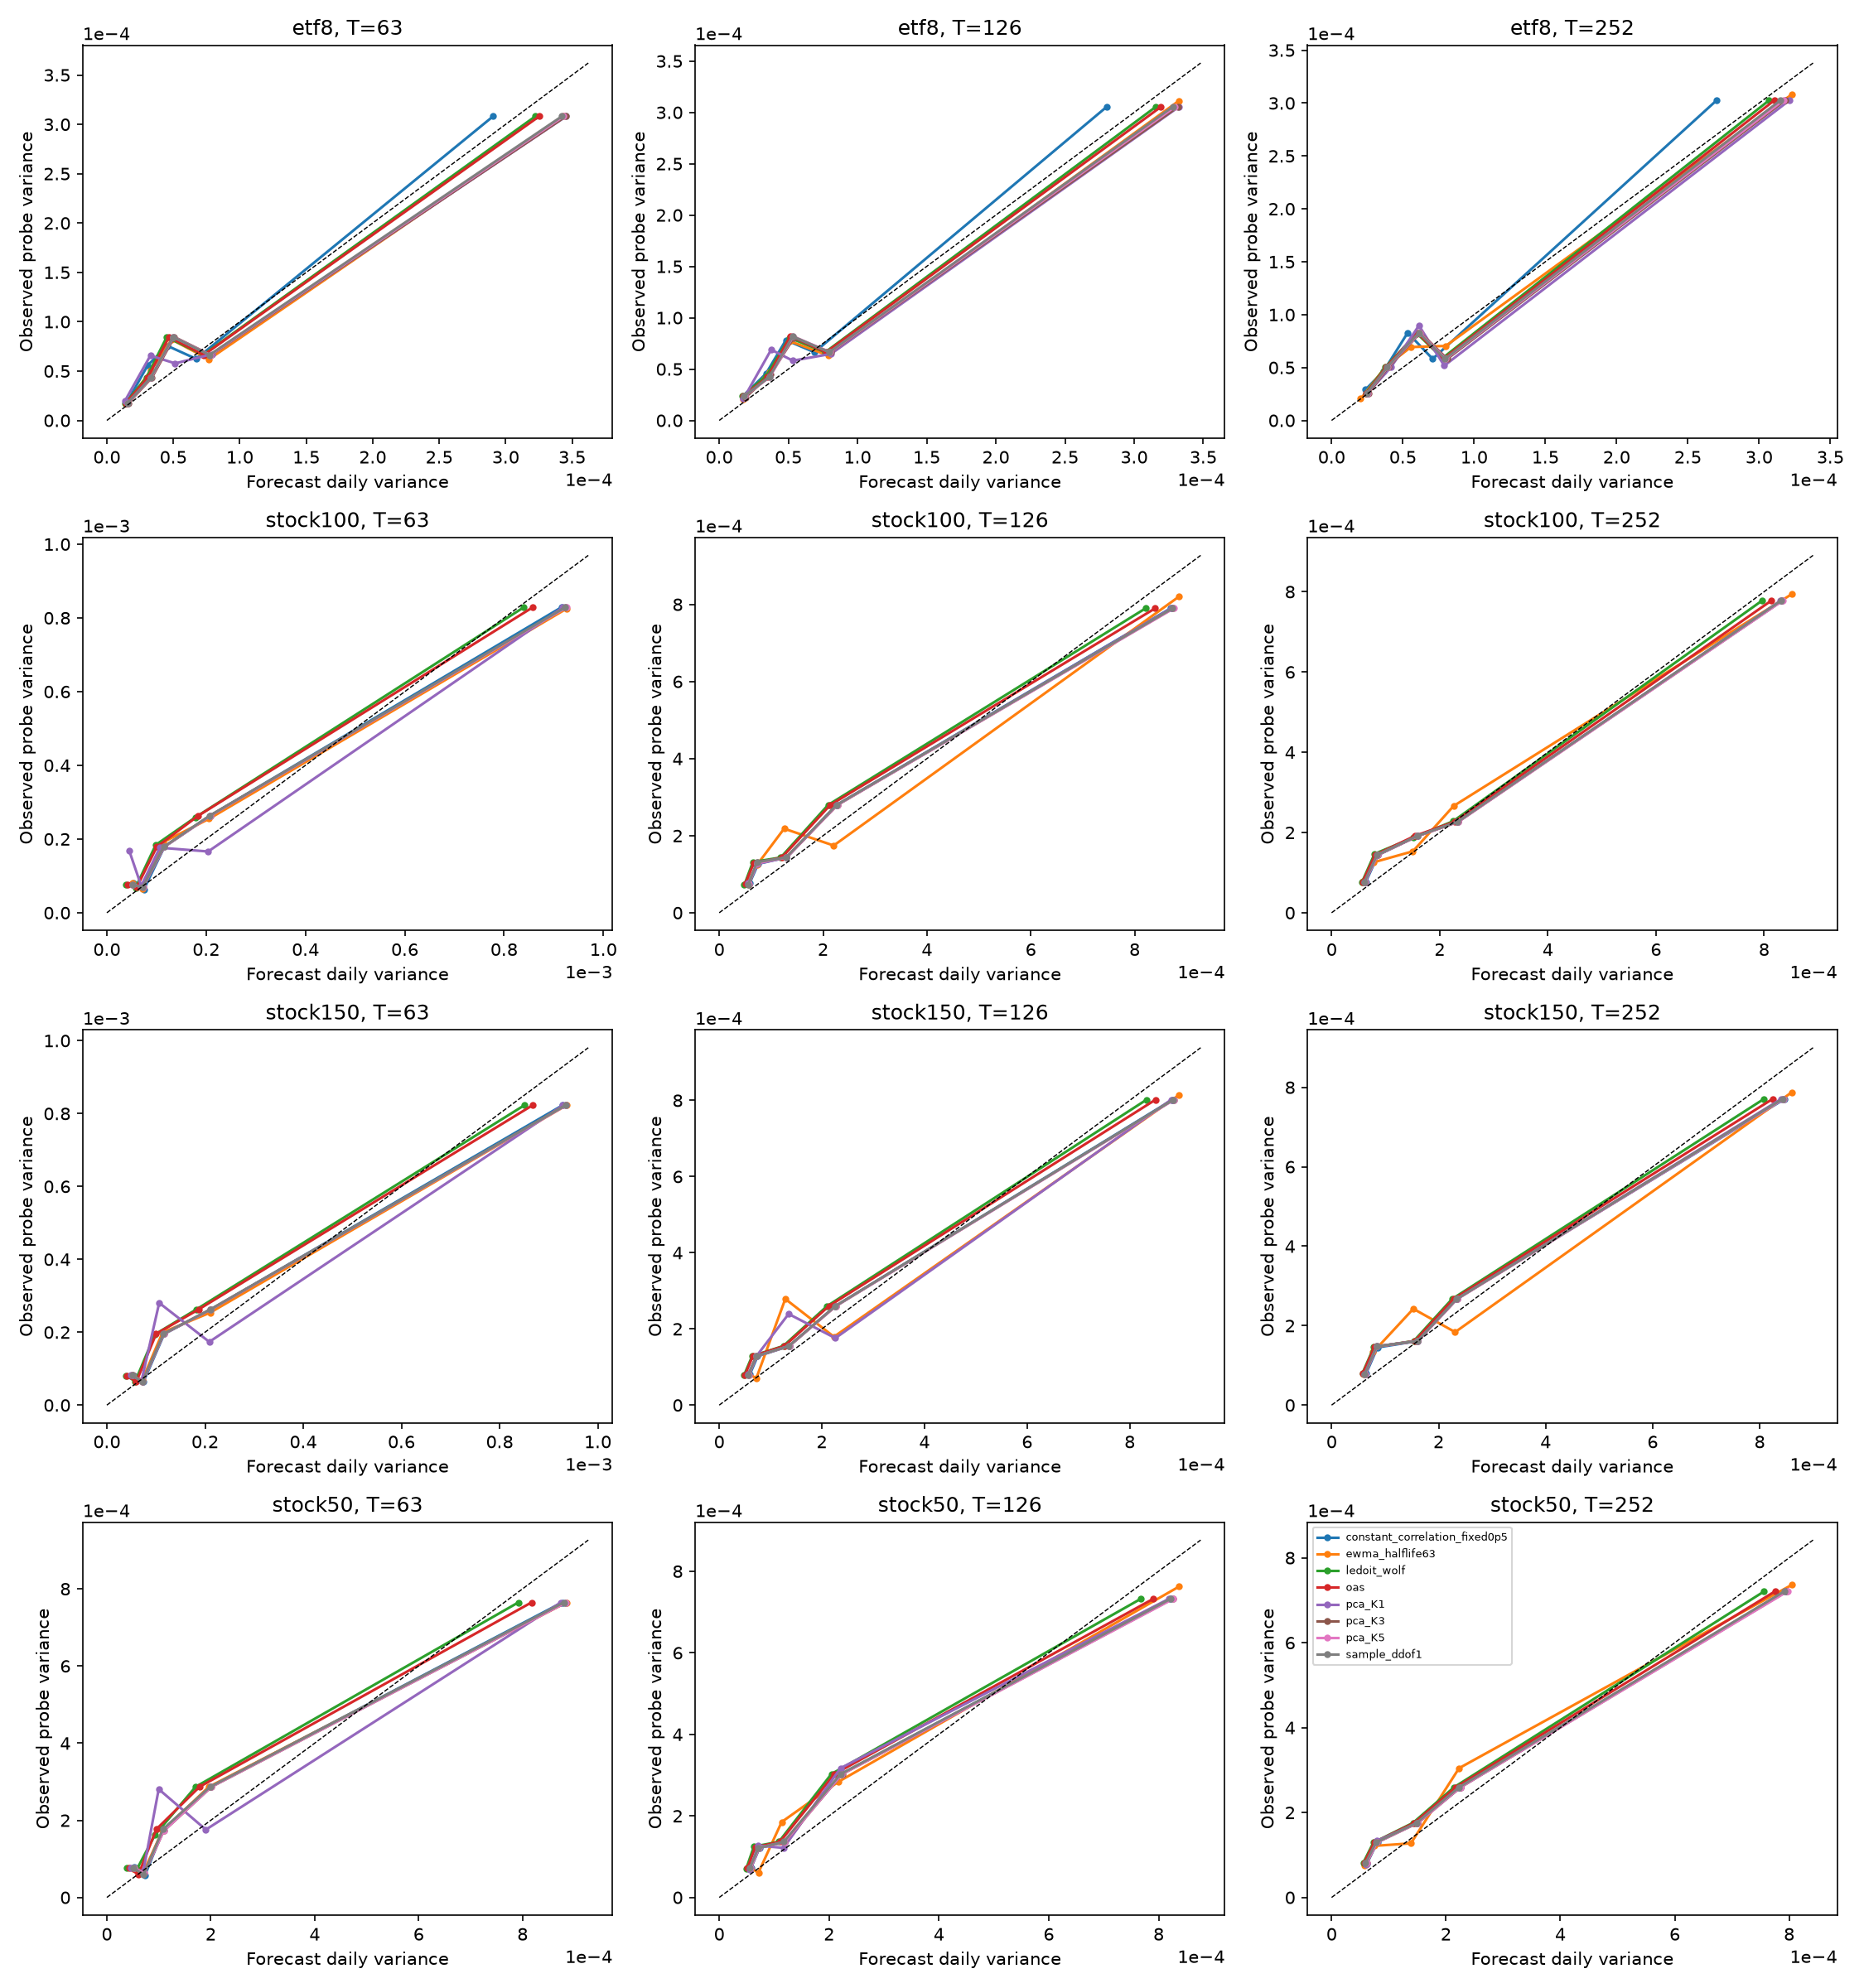

In [5]:
from IPython.display import Image
calibration = root/'reports/risk_forecast_calibration_v1'
audit = json.loads((calibration/'export-manifest.json').read_text())
assert (calibration/'COMPLETE').read_text().strip() == sha(calibration/'export-manifest.json')
for name, expected in audit['outputs_sha256'].items():
    assert sha(calibration/name) == expected
full = pd.read_csv(calibration/'all_forecast_scores.csv', float_precision='round_trip')
assert len(full) == 9120 and full.score_status.eq('valid').sum() == 8808
display(full.groupby(['panel','lookback','score_status']).size().unstack(fill_value=0))
display(Image(filename=str(calibration/'variance_calibration.png')))

,panel,lookback,recipe,block_months,paired_months,mean_difference,lower,upper
3,etf8,63,ewma_halflife63,3,94,-0.015331,-0.045451,0.004389
4,etf8,63,ewma_halflife63,6,94,-0.015331,-0.047641,0.004206
5,etf8,63,ewma_halflife63,12,94,-0.015331,-0.045972,0.003722
27,etf8,126,ewma_halflife63,3,94,-0.069356,-0.172297,-0.009189
28,etf8,126,ewma_halflife63,6,94,-0.069356,-0.157470,-0.015803
29,etf8,126,ewma_halflife63,12,94,-0.069356,-0.152232,-0.015188
51,etf8,252,ewma_halflife63,3,94,-0.131820,-0.289814,-0.028408
52,etf8,252,ewma_halflife63,6,94,-0.131820,-0.275815,-0.034058
53,etf8,252,ewma_halflife63,12,94,-0.131820,-0.261575,-0.045275
75,stock100,63,ewma_halflife63,3,91,-0.020448,-0.045481,-0.001101


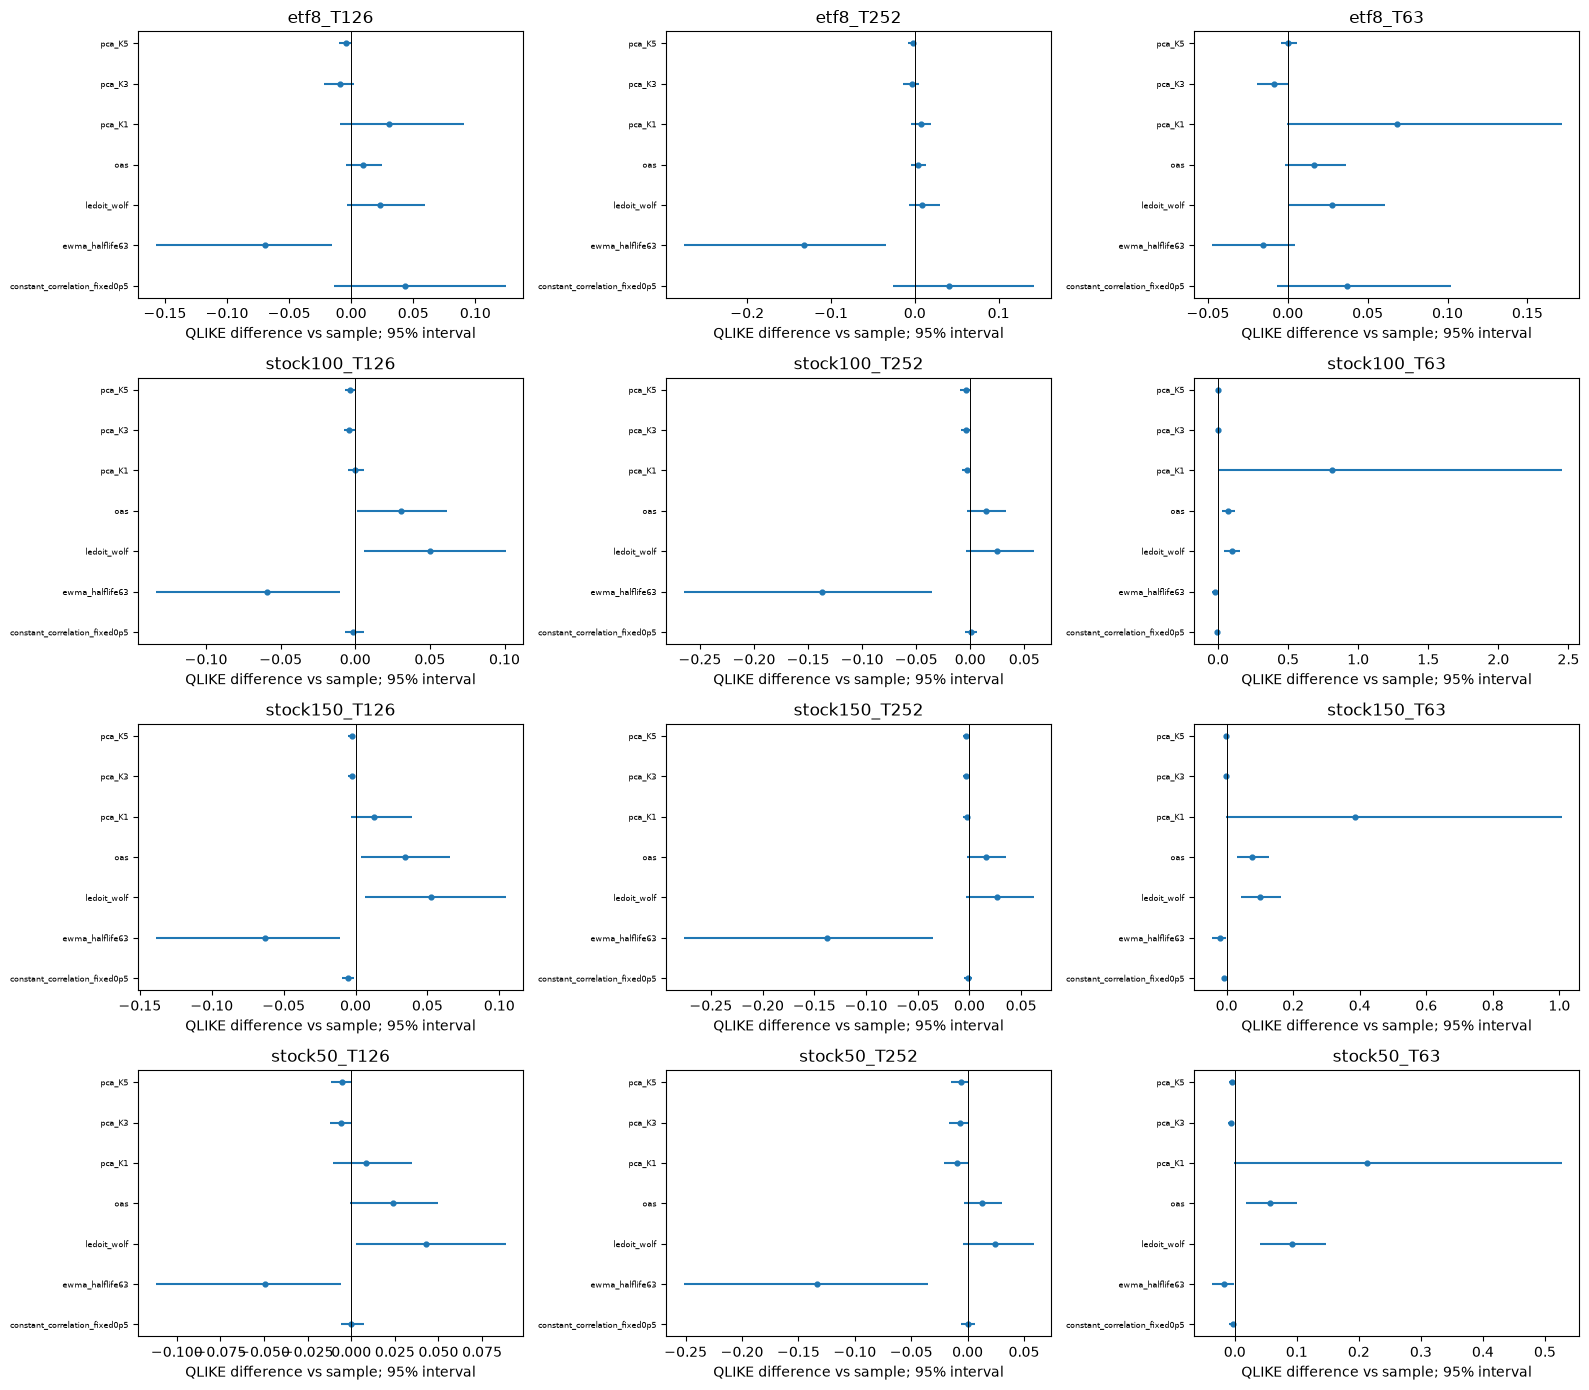

In [6]:
intervals = pd.read_csv(calibration/'paired_loss_intervals.csv')
assert len(intervals) == 288
display(intervals[intervals.recipe.eq('ewma_halflife63')].round(6))
selected = intervals[intervals.block_months.eq(6) & ~intervals.recipe.eq('sample_ddof1')].copy()
selected['label'] = selected.panel + '_T' + selected.lookback.astype(str)
fig, axes = plt.subplots(4,3,figsize=(16,14))
for ax, (label, group) in zip(axes.flat, selected.groupby('label'), strict=True):
    y = np.arange(len(group))
    ax.hlines(y, group.lower, group.upper)
    ax.scatter(group.mean_difference,y,s=12)
    ax.axvline(0,color='black',lw=.7)
    ax.set_yticks(y,group.recipe,fontsize=6)
    ax.set_title(label)
    ax.set_xlabel('QLIKE difference vs sample; 95% interval')
plt.tight_layout()
plt.show()

## Calendar-year stability

Every year uses the common mature dates for all eight recipes. These descriptive development slices show whether an aggregate loss difference persists over time; no year is removed or used to tune a model.

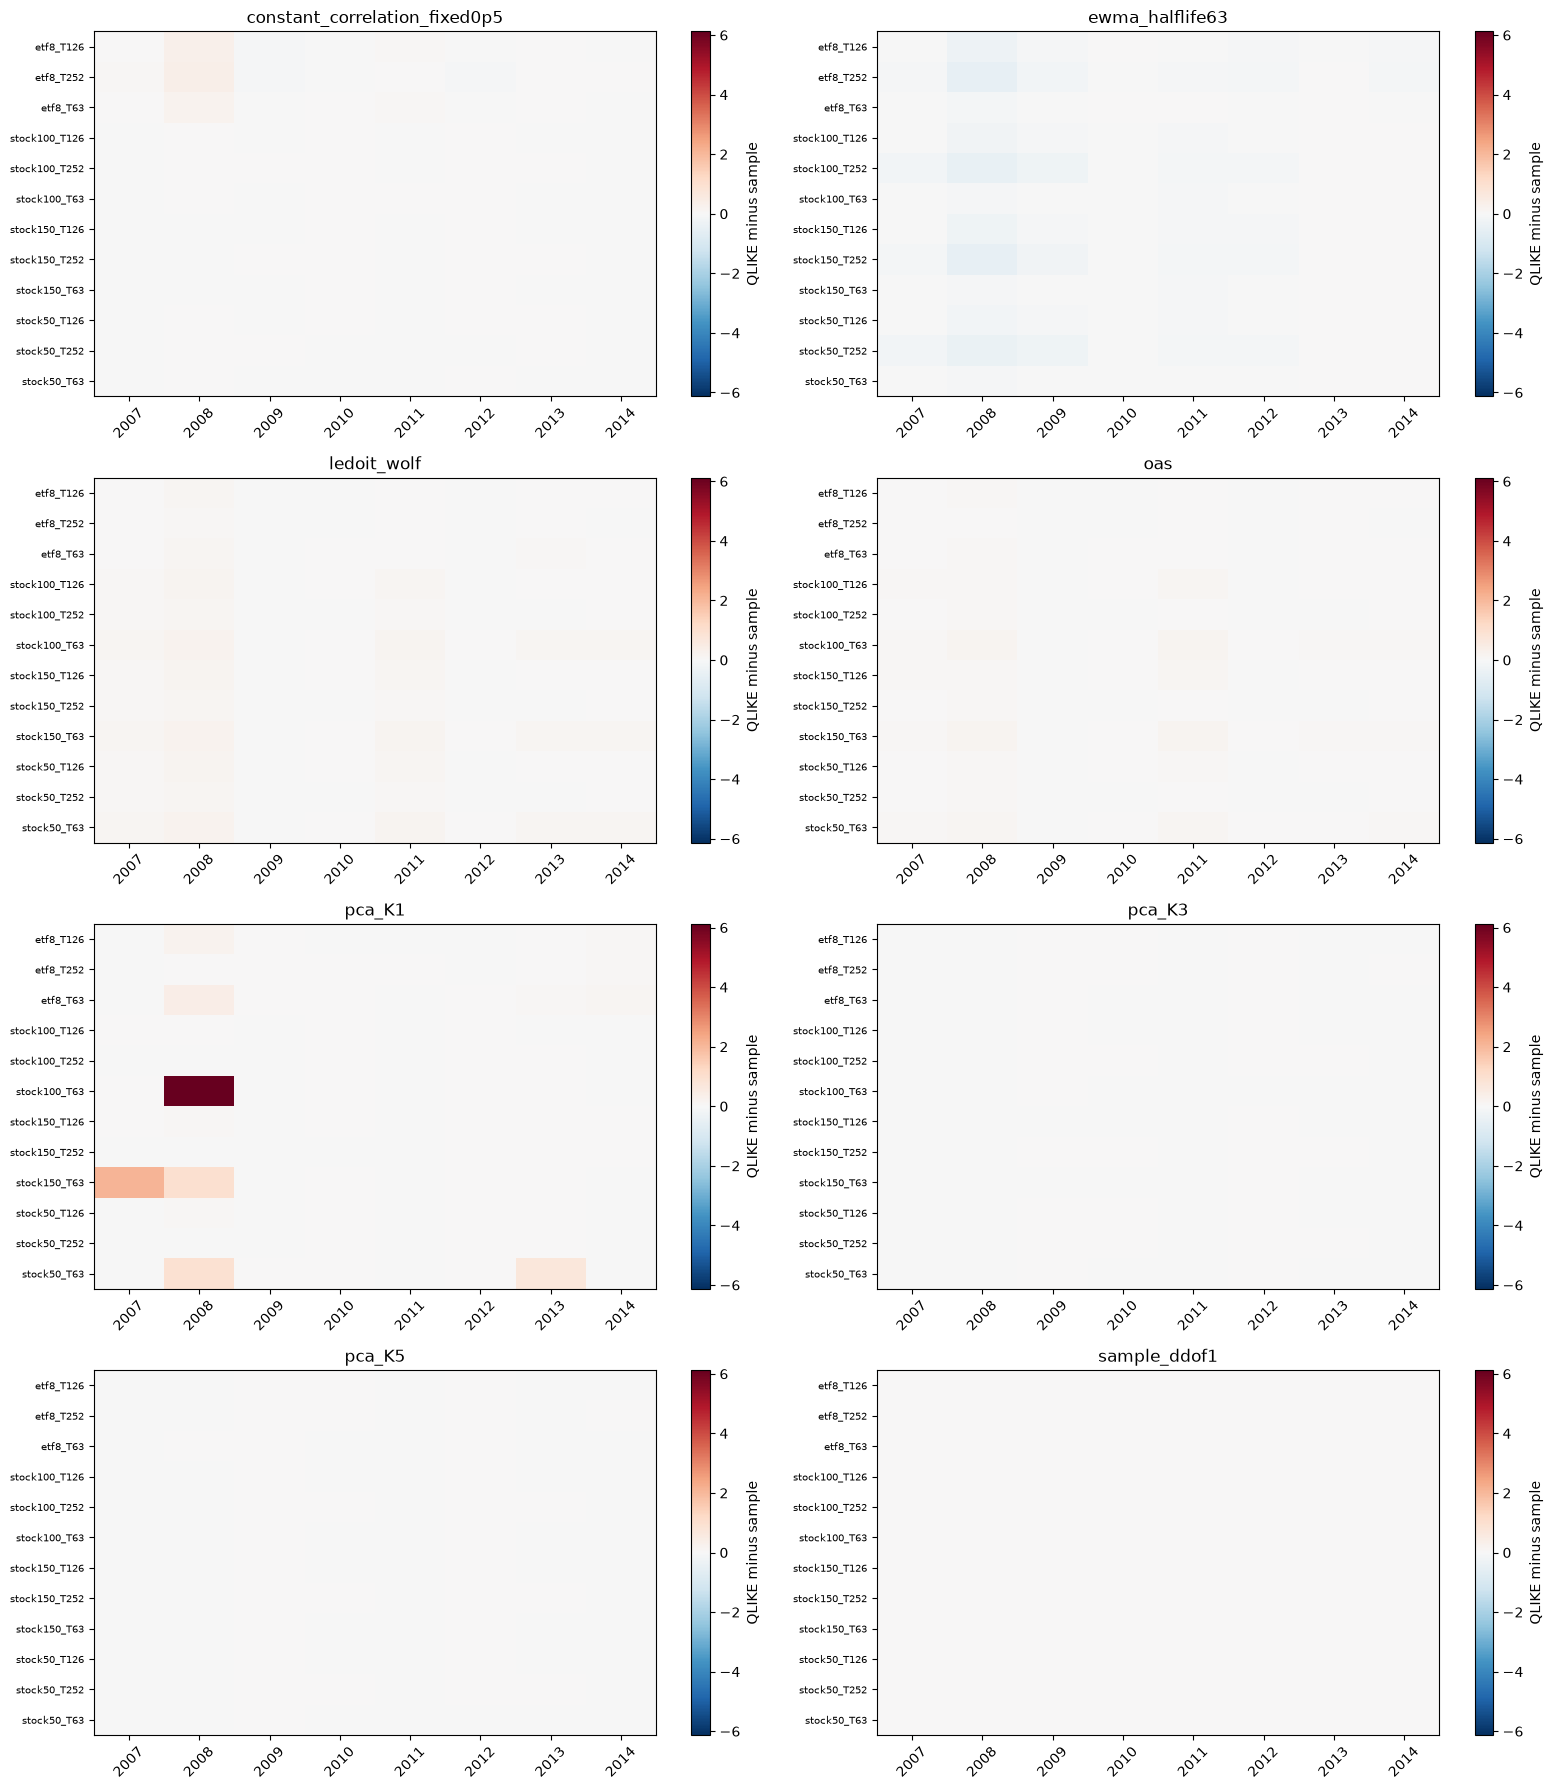

year,2007,2008,2009,2010,2011,2012,2013,2014
panel_window,,,,,,,,
etf8_T126,11,12,12,12,12,12,12,11
etf8_T252,11,12,12,12,12,12,12,11
etf8_T63,11,12,12,12,12,12,12,11
stock100_T126,11,12,12,11,11,12,11,11
stock100_T252,11,12,12,11,11,12,11,11
stock100_T63,11,12,12,11,11,12,11,11
stock150_T126,11,12,12,11,11,11,11,11
stock150_T252,11,12,12,11,11,11,11,11
stock150_T63,11,12,12,11,11,11,11,11


In [7]:
annual = pd.read_csv(calibration/'annual_paired_losses.csv')
assert len(annual) == 768
annual['panel_window'] = annual.panel + '_T' + annual.lookback.astype(str)
fig, axes = plt.subplots(4,2,figsize=(16,18))
bound = annual.mean_difference.abs().max()
for ax, (recipe, group) in zip(axes.flat, annual.groupby('recipe'), strict=True):
    table = group.pivot(index='panel_window', columns='year', values='mean_difference')
    image = ax.imshow(table,aspect='auto',cmap='RdBu_r', vmin=-bound,vmax=bound)
    ax.set_xticks(range(len(table.columns)),table.columns,rotation=45)
    ax.set_yticks(range(len(table)),table.index,fontsize=7)
    ax.set_title(recipe)
    fig.colorbar(image,ax=ax,label='QLIKE minus sample')
plt.tight_layout()
plt.show()
display(annual.groupby(['panel_window','year']).paired_months.first().unstack())